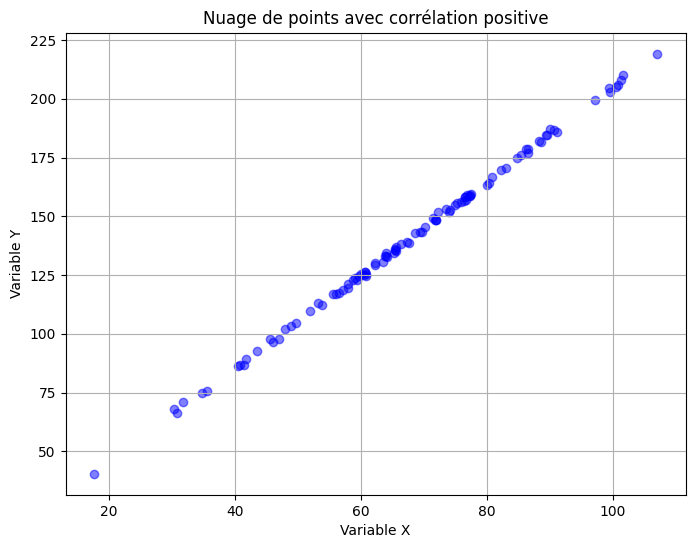

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Génération aléatoire de données dans les plages spécifiées
np.random.seed(42)
num_points = 100
x = np.random.normal(70, 20, num_points)
y = 2 * x +5 + np.random.normal(0, 1, num_points)  # Une corrélation positive avec un peu de bruit

# Création du nuage de points
plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='blue', alpha=0.5)
plt.title("Nuage de points avec corrélation positive")
plt.xlabel("Variable X")
plt.ylabel("Variable Y")
plt.grid(True)
plt.show()


In [5]:
import statsmodels.api as sm

In [7]:
X_OLS = sm.add_constant(x)

model = sm.OLS(endog=y, exog=X_OLS)
model_fit = model.fit()
print(model_fit.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 1.439e+05
Date:                Mon, 06 Oct 2025   Prob (F-statistic):          5.28e-157
Time:                        14:29:46   Log-Likelihood:                -135.71
No. Observations:                 100   AIC:                             275.4
Df Residuals:                      98   BIC:                             280.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.5088      0.369     14.917      0.0

Illustration de la régression

Taille & Poids \\
60     & 84    \\
62     & 95    \\
64     & 140   \\
66     & 155   \\
68     & 119   \\
70     & 175   \\
72     & 145   \\
74     & 197   \\
76     & 150  


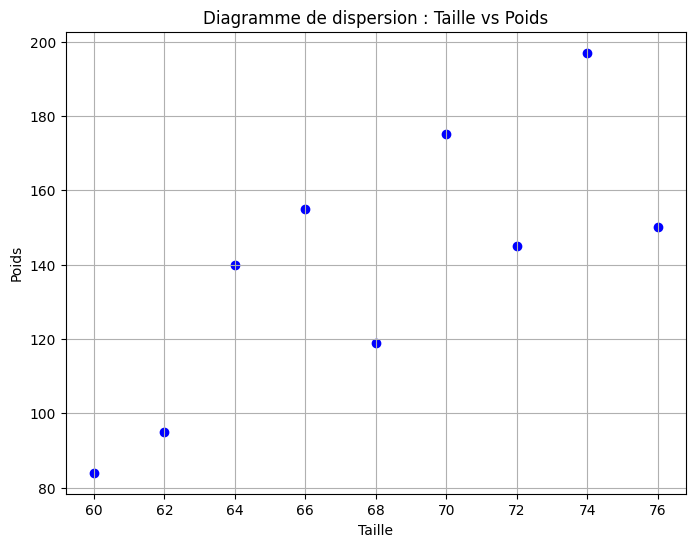

In [8]:
import matplotlib.pyplot as plt

# Données de taille et de poids
tailles = [60, 62, 64, 66, 68, 70, 72, 74, 76]
poids = [84, 95, 140, 155, 119, 175, 145, 197, 150]

# Création d'un diagramme de dispersion
plt.figure(figsize=(8, 6))
plt.scatter(tailles, poids, color='blue', marker='o')
plt.title('Diagramme de dispersion : Taille vs Poids')
plt.xlabel('Taille')
plt.ylabel('Poids')
plt.grid(True)
plt.show()


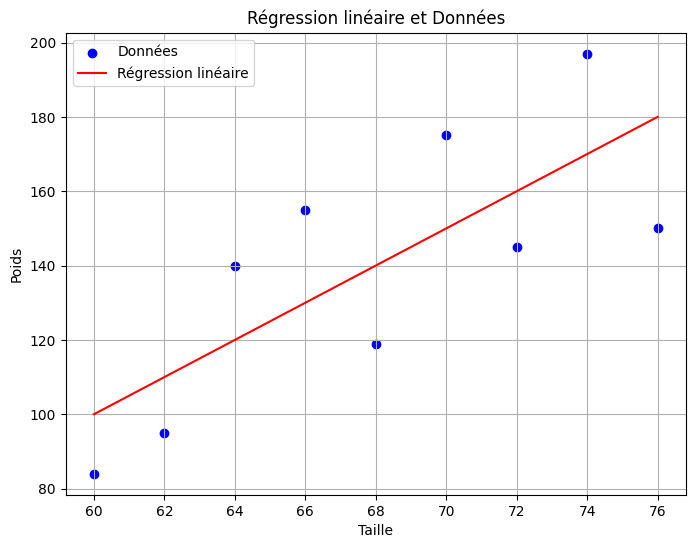

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Données de taille et de poids
tailles = [60, 62, 64, 66, 68, 70, 72, 74, 76]
poids = [84, 95, 140, 155, 119, 175, 145, 197, 150]

# Calcul de la régression linéaire
coefficients = np.polyfit(tailles, poids, 1)
pente = coefficients[0]
intercept = coefficients[1]

# Calcul des prédictions basées sur la régression linéaire
predictions = np.polyval(coefficients, tailles)

# Création d'un diagramme de dispersion avec la droite de régression
plt.figure(figsize=(8, 6))
plt.scatter(tailles, poids, color='blue', marker='o', label='Données')
plt.plot(tailles, predictions, color='red', label='Régression linéaire')

plt.title('Régression linéaire et Données')
plt.xlabel('Taille')
plt.ylabel('Poids')
plt.grid(True)
plt.legend()
plt.show()



In [10]:
import statsmodels.api as sm
import numpy as np
import pandas as pd

# Creating a DataFrame
data = {'tailles': [60, 62, 64, 66, 68, 70, 72, 74, 76],
        'poids': [84, 95, 140, 155, 119, 175, 145, 197, 150]}

df = pd.DataFrame(data)

# Adding a constant column
df['constant'] = 1

# Separating the features (X) and target (y)
X = df[['constant', 'tailles']]
y = df['poids']


X_OLS = sm.add_constant(tailles)

model = sm.OLS(endog=y, exog=X)
model_fit = model.fit()
print(model_fit.summary())

                            OLS Regression Results                            
Dep. Variable:                  poids   R-squared:                       0.575
Model:                            OLS   Adj. R-squared:                  0.515
Method:                 Least Squares   F-statistic:                     9.489
Date:                Mon, 06 Oct 2025   Prob (F-statistic):             0.0178
Time:                        14:46:12   Log-Likelihood:                -40.662
No. Observations:                   9   AIC:                             85.32
Df Residuals:                       7   BIC:                             85.72
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
constant    -200.0000    110.690     -1.807      0.1

Calculer l'estimateur de l'écart type des résidus $s$ pour notre modèle

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Données de taille et de poids
tailles = [60, 62, 64, 66, 68, 70, 72, 74, 76]
poids = [84, 95, 140, 155, 119, 175, 145, 197, 150]


# Définition du modèle
def pred1(X):
  return(5*X-200)

# Définition du modèle
def pred2(X):
  return(4*X - 125)


# Calcul des erreurs d'échantillons
erreurs_d_echantillons = poids - pred1(np.array(tailles))

print(erreurs_d_echantillons)

estimateur_ecart_type_d_echantillon = np.sqrt(np.sum((erreurs_d_echantillons)**2)/(len(tailles)-2))
print(estimateur_ecart_type_d_echantillon)

[-16 -15  20  25 -21  25 -15  27 -30]
25.145292089886613


IC pour observations collectées dans l'échantillons d'entraînement

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Données de taille et de poids
tailles = [60, 62, 64, 66, 68, 70, 72, 74, 76]
poids = [84, 95, 140, 155, 119, 175, 145, 197, 150]

# Calcul de la régression linéaire
coefficients = np.polyfit(tailles, poids, 1)
pente = coefficients[0]
intercept = coefficients[1]
print("pente" , pente)
print("intercept" , intercept)

# Calcul des prédictions basées sur la régression linéaire
predictions = np.polyval(coefficients, tailles)

n = len(tailles)
x_mean = np.mean(tailles)

print("x_mean" , x_mean)
stderr = np.sqrt(np.sum((poids - predictions) ** 2) / (n - 2))
print('s' , stderr)


# Prédiction de la moyenne des réponses pour x_0 fixé
t_value = stats.t.ppf(0.975, df=n - 2)  # Pour un intervalle de confiance à 95%
print("t_value " , t_value )

ind = 8
x_0 = tailles[ind]
print("x0 : taille ", x_0)
sc_xx =  np.sum((tailles -x_mean)**2)
print("sc_xx :", sc_xx)

s_hat_y = stderr * np.sqrt((1/n) + (((x_0 - x_mean)**2)/sc_xx))


print('s_hat_y',s_hat_y)

print('IC  de poids pour taille ',x_0)
print('erreur type estimée',t_value* s_hat_y)
print('upper bound', pente * x_0 + intercept + t_value* s_hat_y)
print('lower bound', pente * x_0 + intercept - t_value* s_hat_y)
print('true val ' , poids[ind])


pente 5.000000000000002
intercept -200.0000000000001
x_mean 68.0
s 25.145292089886613
t_value  2.3646242515927844
x0 : taille  76
sc_xx : 240.0
s_hat_y 15.455209220954988
IC  de poids pour taille  76
erreur type estimée 36.54576253731059
upper bound 216.5457625373106
lower bound 143.4542374626894
true val  150


In [ ]:
# Prédiction pour toutes les observation
s_hat_all_y = stderr * np.sqrt((1/n) + (((tailles - x_mean)**2)/sc_xx))
y_upper = []
y_lower = []
for i in range(len(tailles)):
  y_upper.append(  pente * tailles[i] + intercept + t_value* s_hat_all_y[i])
  y_lower.append(  pente * tailles[i] + intercept - t_value* s_hat_all_y[i])


print(y_upper)
print(y_lower)
print(poids)


[136.54576252830816, 140.38305924612678, 145.07018626623585, 151.25428449950334, 159.81972249149445, 171.25428449950334, 185.07018626623585, 200.38305924612678, 216.54576252830816]
[63.45423747169184, 79.61694075387324, 94.92981373376414, 108.74571550049666, 120.18027750850555, 128.74571550049666, 134.92981373376415, 139.61694075387322, 143.45423747169184]
[84, 95, 140, 155, 119, 175, 145, 197, 150]


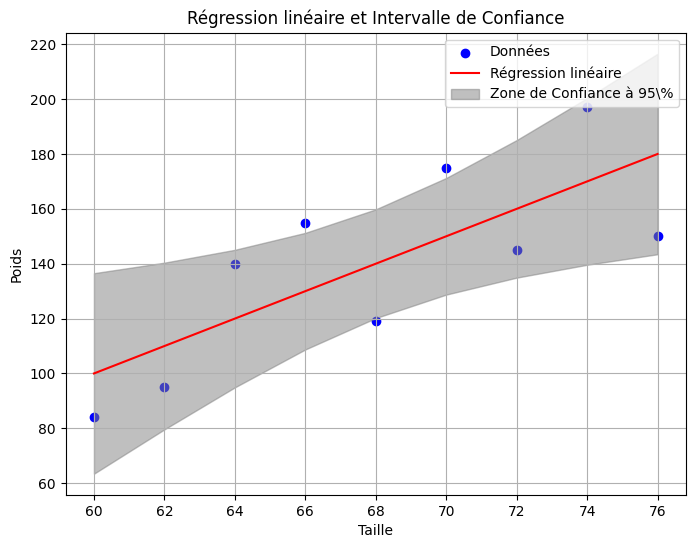

In [ ]:

# Création d'un diagramme de dispersion avec la droite de régression et l'intervalle de confiance
plt.figure(figsize=(8, 6))
plt.scatter(tailles, poids, color='blue', marker='o', label='Données')
plt.plot(tailles, predictions, color='red', label='Régression linéaire')

# Tracer l'intervalle de confiance
# Ajouter la zone grisée entre upper_bound et lower_bound
plt.fill_between(tailles, y_lower, y_upper, color='gray', alpha=0.5, label='Zone de Confiance à 95\%')


plt.title('Régression linéaire et Intervalle de Confiance')
plt.xlabel('Taille')
plt.ylabel('Poids')
plt.grid(True)
plt.legend()
plt.show()


Nouvel étudiant

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Données de taille et de poids
tailles = [60, 62, 64, 66, 68, 70, 72, 74, 76]
poids = [84, 95, 140, 155, 119, 175, 145, 197, 150]

# Calcul de la régression linéaire
coefficients = np.polyfit(tailles, poids, 1)
pente = coefficients[0]
intercept = coefficients[1]
print("pente" , pente)
print("intercept" , intercept)

# Calcul des prédictions basées sur la régression linéaire
predictions = np.polyval(coefficients, tailles)

n = len(tailles)
x_mean = np.mean(tailles)

print("x_mean" , x_mean)
stderr = np.sqrt(np.sum((poids - predictions) ** 2) / (n - 2))
print('s' , stderr)


# Prédiction de l'IC pour une nouvelle observation
t_value = stats.t.ppf(0.975, df=n - 2)  # Pour un intervalle de confiance à 95%
print("t_value " , t_value )

x_new = 76
print("xnew : taille ", x_new)
sc_xx =  np.sum((tailles -x_mean)**2)
print("sc_xx :", sc_xx)

s_y_new = stderr * np.sqrt(1 + (1/n) + (((x_new - x_mean)**2)/sc_xx))

print('IC  de poids pour taille ',x_new )
print('erreur type estimée',t_value* s_y_new)
print('upper bound', pente * x_new  + intercept + t_value* s_y_new)
print('lower bound', pente * x_new  + intercept - t_value* s_y_new)



pente 5.000000000000002
intercept -200.0000000000001
x_mean 68.0
s 25.145292089886613
t_value  2.3646242510102993
xnew : taille  76
sc_xx : 240.0
IC  de poids pour taille  76
erreur type estimée 69.79244483132935
upper bound 249.79244483132936
lower bound 110.20755516867065


249.79244483132936
110.20755516867065


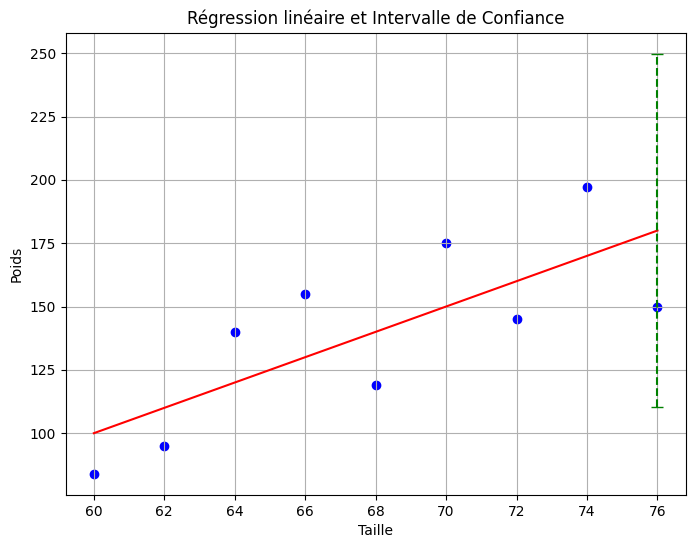

In [ ]:
upper_bound = pente * x_new  + intercept + t_value* s_y_new
lower_bound =  pente * x_new  + intercept - t_value* s_y_new
print(upper_bound)
print(lower_bound)


# Création d'un diagramme de dispersion avec la droite de régression et l'intervalle de confiance
plt.figure(figsize=(8, 6))
plt.scatter(tailles, poids, color='blue', marker='o', label='Données')
plt.plot(tailles, predictions, color='red', label='Régression linéaire')


# Tracez le segment vertical
plt.vlines(x=x_new, ymin=lower_bound , ymax=upper_bound , color='green', linestyle='--', label='Segment Vertical')
# Tracez des marqueurs (délimitations) aux extrémités du segment
plt.plot(x_new, upper_bound , marker="_", markersize=8, color='green', label='Délimitation Bas')
plt.plot(x_new, lower_bound, marker="_", markersize=8, color='green', label='Délimitation Haut')


# Afficher le graphique
plt.title('Régression linéaire et Intervalle de Confiance')
plt.xlabel('Taille')
plt.ylabel('Poids')
plt.grid(True)
plt.show()


F-Statistique

In [ ]:
import numpy as np
import pandas as pd

# Creating a DataFrame
data = {'tailles': [60, 62, 64, 66, 68, 70, 72, 74, 76],
        'poids': [84, 95, 140, 155, 119, 175, 145, 197, 150]}

df = pd.DataFrame(data)

# Adding a constant column
df['constant'] = 1

# Separating the features (X) and target (y)
X = df[['constant', 'tailles']]
y = df['poids']

# Calculate the Residual Sum of Squares (RSS)
import statsmodels.api as sm

X_OLS = sm.add_constant(df['tailles'])
model = sm.OLS(endog=y, exog=X_OLS)
model_fit = model.fit()

y_hat = model_fit.fittedvalues
sc_yy = np.sum((y - y_hat) ** 2)
print("sc_yy",sc_yy  )
# Calculate the Explained Sum of Squares (ESS)
y_mean = np.mean(y)
ess = np.sum((y_hat - y_mean) ** 2)
print("ess",ess)

# Calculate degrees of freedom
df1 = X.shape[1] - 1  # Number of independent variables (excluding constant)
print("df1", df1)
df2 = X.shape[0] - df1 - 1  # Total observations - df1 - 1
print("df2", df2)

# Calculate Mean Squares
ms1 = ess / df1
print("ms1" , ms1)
ms2 = sc_yy / df2
print("ms2" , ms2)
# Calculate the F-statistic
f_statistic = ms1 / ms2

print("F-statistic:", f_statistic)


sc_yy 4426.0
ess 6000.000000000007
df1 1
df2 7
ms1 6000.000000000007
ms2 632.2857142857143
F-statistic: 9.489380930863092


In [ ]:
from scipy import stats

# Set the significance level (alpha)
alpha = 0.05  # For a 95% confidence level

# Calculate the critical value from the F-distribution
critical_value = stats.f.ppf(1 - alpha, dfn=df1, dfd=df2)

print("F-statistic:", f_statistic)
print("Critical Value:", critical_value)

# Compare the computed F-statistic with the critical value
if f_statistic > critical_value:
    print("Reject the null hypothesis. The model is statistically significant.")
else:
    print("Fail to reject the null hypothesis. The model is not statistically significant.")


F-statistic: 9.489380930863092
Critical Value: 5.591447851220738
Reject the null hypothesis. The model is statistically significant.
